# DSA 4060 Practical Quiz: Personalized Movie Recommender

**Name:** Iranzi Innocent  
**Student ID:** 670513  
**Assigned User ID:** 14

The last two digits of the Student ID are 13. The assigned user is calculated as $(13 \bmod 40) + 1 = 14$. Every later step uses only this user.

**Objective.** Analyse User 14's ratings, identify preferred genres, and recommend five movies the user has not already rated.

## Setup

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

NAME = "Iranzi Innocent"
STUDENT_ID = "670513"
ASSIGNED_USER_ID = (int(STUDENT_ID[-2:]) % 40) + 1

print("Name:", NAME)
print("Student ID:", STUDENT_ID)
print("Last two digits:", STUDENT_ID[-2:])
print("Assigned User ID = (13 MOD 40) + 1 =", ASSIGNED_USER_ID)
assert ASSIGNED_USER_ID == 14

Name: Iranzi Innocent
Student ID: 670513
Last two digits: 13
Assigned User ID = (13 MOD 40) + 1 = 14


## Task 1 – Load and inspect the data

The catalogue is `movies.csv`. The interaction history is `ratings.csv`. Both files sit in the same folder as this notebook.

In [2]:
DATA_DIR = Path(".")
movies = pd.read_csv(DATA_DIR / "movies.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")

print("First five rows of movies.csv")
display(movies.head())
print("First five rows of ratings.csv")
display(ratings.head())

First five rows of movies.csv


,movie_id,title,genres
0,1,Inception,Sci-Fi|Thriller
1,2,Interstellar,Sci-Fi|Drama
2,3,The Matrix,Sci-Fi|Action
3,4,Arrival,Sci-Fi|Drama
4,5,Edge of Tomorrow,Sci-Fi|Action


First five rows of ratings.csv


,user_id,movie_id,rating
0,1,2,3.500
1,1,3,4.500
2,1,5,3.500
3,1,6,3.500
4,1,11,3.000


In [3]:
print("movies.csv rows and columns:", movies.shape)
print("ratings.csv rows and columns:", ratings.shape)
print()
print("movies.csv columns:", list(movies.columns))
print("ratings.csv columns:", list(ratings.columns))
print()
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies in the catalogue:", movies["movie_id"].nunique())
print("Unique movies with at least one rating:", ratings["movie_id"].nunique())
print("Rating range:", ratings["rating"].min(), "to", ratings["rating"].max())

movies.csv rows and columns: (36, 3)
ratings.csv rows and columns: (440, 3)

movies.csv columns: ['movie_id', 'title', 'genres']
ratings.csv columns: ['user_id', 'movie_id', 'rating']

Unique users: 40
Unique movies in the catalogue: 36
Unique movies with at least one rating: 36
Rating range: 1.5 to 5.0


In [4]:
print("Missing values in movies.csv")
print(movies.isna().sum())
print()
print("Missing values in ratings.csv")
print(ratings.isna().sum())
print()
print("Duplicate movie rows:", int(movies.duplicated().sum()))
print("Duplicate movie_id values:", int(movies["movie_id"].duplicated().sum()))
print("Duplicate rating rows:", int(ratings.duplicated().sum()))
print("Duplicate user-movie pairs:", int(ratings.duplicated(["user_id", "movie_id"]).sum()))
print("Ratings pointing at unknown movie IDs:", int((~ratings["movie_id"].isin(movies["movie_id"])).sum()))

Missing values in movies.csv
movie_id    0
title       0
genres      0
dtype: int64

Missing values in ratings.csv
user_id     0
movie_id    0
rating      0
dtype: int64

Duplicate movie rows: 0
Duplicate movie_id values: 0
Duplicate rating rows: 0
Duplicate user-movie pairs: 0
Ratings pointing at unknown movie IDs: 0


**Task 1 findings.** `movies.csv` has 36 rows and 3 columns (`movie_id`, `title`, `genres`). `ratings.csv` has 440 rows and 3 columns (`user_id`, `movie_id`, `rating`). There are 40 users and 36 catalogue movies, and every movie has at least one rating. Ratings run from 1.5 to 5.0.

Neither file has missing values. There are no duplicate movie IDs, no duplicate rating rows, and no repeated user-movie pairs. Every `movie_id` in the ratings file exists in the catalogue, so a later join will not create untitled recommendations. No rows were removed.

## Task 2 – Profile User 14

The profile uses only ratings where `user_id` is 14.

In [5]:
user_ratings = ratings[ratings["user_id"] == ASSIGNED_USER_ID].copy()
user_movies = user_ratings.merge(movies, on="movie_id", how="left", validate="many_to_one")
user_movies = user_movies.sort_values(["rating", "title"], ascending=[False, True]).reset_index(drop=True)

print("Number of movies rated by User", ASSIGNED_USER_ID, ":", len(user_movies))
display(user_movies[["movie_id", "title", "genres", "rating"]])

Number of movies rated by User 14 : 13


,movie_id,title,genres,rating
0,11,Avengers: Endgame,Action|Superhero,4.000
1,3,The Matrix,Sci-Fi|Action,4.000
2,10,Black Panther,Action|Superhero,3.500
3,5,Edge of Tomorrow,Sci-Fi|Action,3.500
4,22,Finding Nemo,Animation|Adventure,3.500
5,8,John Wick,Action|Thriller,3.500
6,32,Jumanji: Welcome to the Jungle,Comedy|Adventure,3.500
7,6,Blade Runner 2049,Sci-Fi|Drama,3.000
8,7,The Dark Knight,Action|Crime,3.000
9,4,Arrival,Sci-Fi|Drama,2.500


### Highest-rated movies

In [6]:
highest_rating = user_movies["rating"].max()
print("Highest rating given by User 14:", highest_rating)

top_two = user_movies[user_movies["rating"] == highest_rating]
print("Movies at the highest rating:")
display(top_two[["title", "genres", "rating"]])

tied_third = user_movies[user_movies["rating"] == 3.5]
print("Tied movies at the next rating (3.5). Any one of these is a valid third title:")
display(tied_third[["title", "genres", "rating"]])

three_highest = pd.concat([top_two, tied_third.head(1)], ignore_index=True)
print("Three highest-rated movies used in the write-up (the two 4.0 films plus Black Panther from the 3.5 tie):")
display(three_highest[["title", "genres", "rating"]])

Highest rating given by User 14: 4.0
Movies at the highest rating:


,title,genres,rating
0,Avengers: Endgame,Action|Superhero,4.000
1,The Matrix,Sci-Fi|Action,4.000


Tied movies at the next rating (3.5). Any one of these is a valid third title:


,title,genres,rating
2,Black Panther,Action|Superhero,3.500
3,Edge of Tomorrow,Sci-Fi|Action,3.500
4,Finding Nemo,Animation|Adventure,3.500
5,John Wick,Action|Thriller,3.500
6,Jumanji: Welcome to the Jungle,Comedy|Adventure,3.500


Three highest-rated movies used in the write-up (the two 4.0 films plus Black Panther from the 3.5 tie):


,title,genres,rating
0,Avengers: Endgame,Action|Superhero,4.000
1,The Matrix,Sci-Fi|Action,4.000
2,Black Panther,Action|Superhero,3.500


### Preferred genres from the ratings

,n_movies,mean_rating,total_rating
genre,,,
Superhero,2,3.750,7.500
Action,6,3.583,21.500
Adventure,2,3.500,7.000
Animation,1,3.500,3.500
Comedy,1,3.500,3.500
Thriller,1,3.500,3.500
Sci-Fi,4,3.250,13.000
Crime,1,3.000,3.000
Biography,1,2.500,2.500


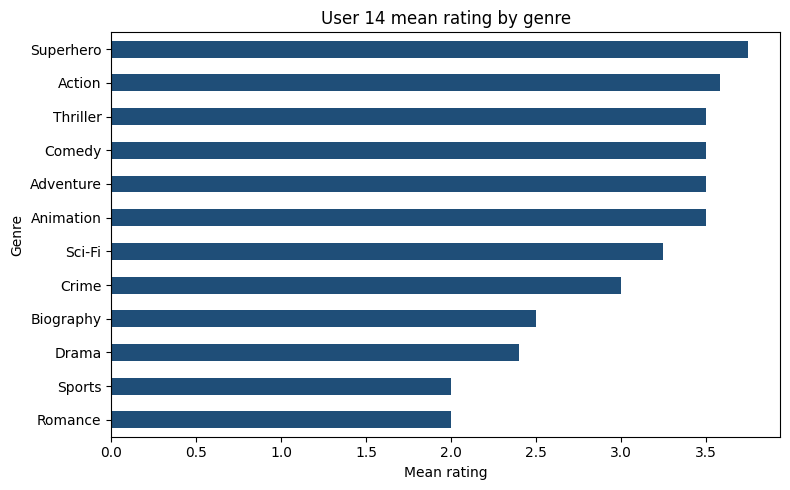

In [7]:
genre_rows = []
for _, row in user_movies.iterrows():
    for genre in row["genres"].split("|"):
        genre_rows.append({"genre": genre, "title": row["title"], "rating": row["rating"]})
genre_evidence = pd.DataFrame(genre_rows)

genre_summary = (
    genre_evidence.groupby("genre")
    .agg(n_movies=("rating", "count"), mean_rating=("rating", "mean"), total_rating=("rating", "sum"))
    .sort_values(["mean_rating", "n_movies"], ascending=False)
)
display(genre_summary)

ax = genre_summary["mean_rating"].sort_values().plot(
    kind="barh",
    color="#1F4E78",
    figsize=(8, 5),
    legend=False,
)
ax.set_title("User 14 mean rating by genre")
ax.set_xlabel("Mean rating")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.show()

**Task 2 interpretation.** User 14 rated 13 movies. The two highest scores are both 4.0: *The Matrix* (Sci-Fi|Action) and *Avengers: Endgame* (Action|Superhero). Five films sit in a tie at 3.5, including *Black Panther*, *Edge of Tomorrow*, and *John Wick*. Any of those 3.5 titles is a valid third highest-rated movie. *Black Panther* is listed here because it continues the Action and Superhero pattern of the 4.0 films.

The preferred genres are **Action** and **Superhero**, with **Sci-Fi** as a supporting taste. Action appears in 6 of the 13 rated movies and has a mean of 3.58. Both 4.0 movies contain Action. Superhero has the highest mean among genres that appear more than once (3.75 from *Endgame* and *Black Panther*). Sci-Fi appears four times, including the 4.0 *Matrix* and the 3.5 *Edge of Tomorrow*, but its mean is pulled down by *Arrival* (2.5).

Drama is the main avoided genre. It appears five times and has a mean of 2.40. The two lowest ratings in the history are *The Notebook* (Romance|Drama, 2.0) and *Remember the Titans* (Sports|Drama, 2.0). Romance, Sports, and Biography are therefore weak evidence of preference, even though they appear in the history.

## Task 3 – Content-based recommendation logic

Movies rated **4.0 or higher** are treated as liked. For User 14 that set contains only *The Matrix* and *Avengers: Endgame*. Those two item profiles become the user profile.

Genres are converted to numbers with **TF-IDF**. Each pipe-separated tag is one token, so `Sci-Fi|Action` is the pair `{Sci-Fi, Action}` and is not split on the hyphen. Cosine similarity then ranks catalogue movies against the mean TF-IDF vector of the liked set. Already-rated movies are removed before the Top 5 is returned.

In [8]:
liked_movies = user_movies[user_movies["rating"] >= 4.0].copy()
print("Liked movies (rating >= 4.0):")
display(liked_movies[["movie_id", "title", "genres", "rating"]])
print("Number of liked movies:", len(liked_movies))

Liked movies (rating >= 4.0):


,movie_id,title,genres,rating
0,11,Avengers: Endgame,Action|Superhero,4.000
1,3,The Matrix,Sci-Fi|Action,4.000


Number of liked movies: 2


In [9]:
vectorizer = TfidfVectorizer(
    tokenizer=lambda text: text.split("|"),
    token_pattern=None,
    lowercase=False,
)
genre_matrix = vectorizer.fit_transform(movies["genres"])
print("TF-IDF feature names (one column per genre):")
print(list(vectorizer.get_feature_names_out()))
print("Genre matrix shape:", genre_matrix.shape)

TF-IDF feature names (one column per genre):
['Action', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Drama', 'Family', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Sports', 'Superhero', 'Thriller']
Genre matrix shape: (36, 16)


In [10]:
liked_positions = movies.index[movies["movie_id"].isin(liked_movies["movie_id"])].tolist()
user_profile = np.asarray(genre_matrix[liked_positions].mean(axis=0))

profile_weights = pd.Series(
    user_profile.ravel(),
    index=vectorizer.get_feature_names_out(),
).sort_values(ascending=False)
print("User 14 profile (mean TF-IDF of liked movies):")
display(profile_weights[profile_weights > 0])

User 14 profile (mean TF-IDF of liked movies):


Action      0.618
Superhero   0.407
Sci-Fi      0.378
dtype: float64

In [11]:
similarity_scores = cosine_similarity(user_profile, genre_matrix).flatten()
scored = movies.copy()
scored["similarity"] = similarity_scores

already_rated_ids = set(user_movies["movie_id"])
unseen = scored[~scored["movie_id"].isin(already_rated_ids)].copy()
unseen = unseen.sort_values(["similarity", "title"], ascending=[False, True])

print("Highest cosine similarities among movies User 14 has not rated:")
display(unseen.head(8)[["movie_id", "title", "genres", "similarity"]])

Highest cosine similarities among movies User 14 has not rated:


,movie_id,title,genres,similarity
11,12,Mission: Impossible - Fallout,Action|Thriller,0.471
8,9,Mad Max: Fury Road,Action|Adventure,0.433
28,29,Sherlock Holmes,Mystery|Action,0.409
1,2,Interstellar,Sci-Fi|Drama,0.370
23,24,Spider-Man: Into the Spider-Verse,Animation|Superhero,0.358
0,1,Inception,Sci-Fi|Thriller,0.312
25,26,A Quiet Place,Horror|Thriller,0.000
22,23,Coco,Animation|Family,0.000


In [12]:
def recommend_for_user(movies, ratings, user_id, n=5, min_like=4.0):
    history = ratings[ratings["user_id"] == user_id].merge(movies, on="movie_id")
    liked = history[history["rating"] >= min_like]
    if liked.empty:
        raise ValueError(f"User {user_id} has no movies rated {min_like} or higher.")

    vectorizer = TfidfVectorizer(
        tokenizer=lambda text: text.split("|"),
        token_pattern=None,
        lowercase=False,
    )
    matrix = vectorizer.fit_transform(movies["genres"])
    liked_positions = movies.index[movies["movie_id"].isin(liked["movie_id"])]
    profile = np.asarray(matrix[liked_positions].mean(axis=0))
    scores = cosine_similarity(profile, matrix).flatten()

    ranked = movies.copy()
    ranked["similarity"] = scores
    ranked = ranked[~ranked["movie_id"].isin(history["movie_id"])]
    ranked = ranked.sort_values(["similarity", "title"], ascending=[False, True]).head(n)
    return ranked[["movie_id", "title", "genres", "similarity"]].reset_index(drop=True)


recommendations = recommend_for_user(movies, ratings, ASSIGNED_USER_ID, n=5)
display(recommendations)

assert len(recommendations) == 5
assert recommendations["movie_id"].is_unique
assert recommendations["movie_id"].isin(user_movies["movie_id"]).sum() == 0
assert recommendations["similarity"].gt(0).all()
print("Checks passed: exactly five unseen movies with positive similarity.")

,movie_id,title,genres,similarity
0,12,Mission: Impossible - Fallout,Action|Thriller,0.471
1,9,Mad Max: Fury Road,Action|Adventure,0.433
2,29,Sherlock Holmes,Mystery|Action,0.409
3,2,Interstellar,Sci-Fi|Drama,0.370
4,24,Spider-Man: Into the Spider-Verse,Animation|Superhero,0.358


Checks passed: exactly five unseen movies with positive similarity.


The five titles are all unrated by User 14. Their similarity is above 0, so each one shares at least one TF-IDF genre with the liked set. Movies such as *Titanic* or *The Hangover* score 0 because they have no Action, Sci-Fi, or Superhero tag, which is consistent with this user's weaker Drama, Romance, and Comedy ratings.

## Task 4 – Explain the recommendations

In [13]:
reasons = {
    "Mission: Impossible - Fallout": (
        "Action is the largest weight in User 14's liked profile, and this title is Action|Thriller. "
        "It is close in genre to John Wick, which the user already rated 3.5."
    ),
    "Mad Max: Fury Road": (
        "The Action tag matches both liked movies. Adventure also appeared at 3.5 in Finding Nemo "
        "and Jumanji, so the second genre is still compatible with the history."
    ),
    "Sherlock Holmes": (
        "Sherlock Holmes is Mystery|Action. The Action overlap with The Matrix and Avengers: Endgame "
        "is what lifts it; Mystery is new, but Action is the user's most frequent high-scoring genre."
    ),
    "Interstellar": (
        "Interstellar is Sci-Fi|Drama. Sci-Fi comes from The Matrix, which was rated 4.0. Drama is a "
        "weaker genre for this user, so the rank is explained by the Sci-Fi overlap rather than by Drama."
    ),
    "Spider-Man: Into the Spider-Verse": (
        "This is Animation|Superhero. Superhero is the highest-mean genre in the profile and is shared "
        "with Avengers: Endgame (4.0) and Black Panther (3.5). The user already rated one animation, "
        "Finding Nemo, at 3.5."
    ),
}

results = recommendations.copy()
results.insert(0, "Rank", range(1, len(results) + 1))
results["Reason"] = results["title"].map(reasons)
results = results.rename(columns={
    "title": "Recommended Movie",
    "genres": "Genres",
})
display(results[["Rank", "Recommended Movie", "Genres", "Reason"]])

,Rank,Recommended Movie,Genres,Reason
0,1,Mission: Impossible - Fallout,Action|Thriller,"Action is the largest weight in User 14's liked profile, and this title is A..."
1,2,Mad Max: Fury Road,Action|Adventure,The Action tag matches both liked movies. Adventure also appeared at 3.5 in ...
2,3,Sherlock Holmes,Mystery|Action,Sherlock Holmes is Mystery|Action. The Action overlap with The Matrix and Av...
3,4,Interstellar,Sci-Fi|Drama,"Interstellar is Sci-Fi|Drama. Sci-Fi comes from The Matrix, which was rated ..."
4,5,Spider-Man: Into the Spider-Verse,Animation|Superhero,This is Animation|Superhero. Superhero is the highest-mean genre in the prof...


| Rank | Recommended Movie | Genres | Reason |
| ---: | --- | --- | --- |
| 1 | Mission: Impossible - Fallout | Action\|Thriller | Highest cosine similarity (0.471) because Action dominates the liked profile. Close to *John Wick*, which User 14 rated 3.5. |
| 2 | Mad Max: Fury Road | Action\|Adventure | Action matches both 4.0 movies. Adventure already appeared in two 3.5 ratings. |
| 3 | Sherlock Holmes | Mystery\|Action | Ranked for the Action overlap with *The Matrix* and *Avengers: Endgame*. |
| 4 | Interstellar | Sci-Fi\|Drama | Sci-Fi is taken from *The Matrix*. Drama is not a preferred genre here, so this title sits below the pure Action matches. |
| 5 | Spider-Man: Into the Spider-Verse | Animation\|Superhero | Superhero matches *Avengers: Endgame* and *Black Panther*. None of these five movies was rated by User 14. |

The ranking is specific to User 14. A user who had liked Romance and Drama would not receive this Action-led list from the same catalogue.

## Task 5 – Critical thinking

**Limitation.** The user profile is built from only two liked movies and from genre tags alone. *The Matrix* and *Avengers: Endgame* share Action, so almost any unseen Action film scores well, including *Sherlock Holmes*, which is a different kind of film from *Endgame*. The model also cannot use the 3.5 ratings as positive evidence, even though *Black Panther* and *Edge of Tomorrow* support the same Action, Superhero, and Sci-Fi pattern. Movies that User 14 scored 2.0, such as *The Notebook*, do not reduce the score of later Drama films; they are only excluded because they have already been rated.

**Improvement.** A practical next step is to weight each movie's TF-IDF vector by its rating, or to treat 3.5 as a like as well as 4.0, so *Black Panther* and *Edge of Tomorrow* would strengthen Superhero and Sci-Fi. Adding a second content field, such as franchise or director, would also separate *Mission: Impossible* from *Sherlock Holmes*. If more users were allowed, collaborative filtering could find people who also rated *The Matrix* and *Endgame* highly and borrow titles they liked that are not obvious genre clones.

## Conclusion

User 14's history is an Action-led profile with Superhero and Sci-Fi support and a clear dislike of Drama, Romance, and Sports. A TF-IDF cosine recommender that uses only movies rated 4.0 or higher therefore returns five unseen Action, Sci-Fi, or Superhero titles: *Mission: Impossible - Fallout*, *Mad Max: Fury Road*, *Sherlock Holmes*, *Interstellar*, and *Spider-Man: Into the Spider-Verse*. The list is personalized to this assigned user and does not repeat any movie already in the rating table.